# Where Is the Retailer Losing Money?
## Using Machine Learning to stop the profit leak — Superstore dataset

**Domain:** Retail & E-commerce  
**Dataset:** Sample Superstore
**Tools:** Python, pandas, matplotlib, seaborn, scikit-learn

### Problem statement
A US retailer sells Furniture, Office Supplies and Technology across 4 regions. Sales look healthy, but many orders lose money. We use machine learning to:

| # | Business question | ML type |
|---|---|---|
| 1 | "If we sell this item at this discount, how much profit will we make?" | **Regression** (predict a number) |
| 2 | "Will this order lose money — yes or no?" | **Classification** (predict a category) |
| 3 | "Which states behave alike, and which are problem states?" | **Clustering** (find groups, no answer given) |

### Roadmap
1. Understand & clean the data → 2. Explore (EDA) → 3. Regression → 4. Classification → 5. Clustering → 6. Cost of not using ML & benefits of ML → 7. Conclusion

---
# Phase 1: Understand and clean the data

In [ ]:
# ---- Step 1.1: Load the data ----
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


file_path = "/content/drive/MyDrive/Batch147_Goutam_singh_Mandloi/ML Assignment/SampleSuperstore.csv"

df = pd.read_csv(file_path)

print("Shape (rows, columns):", df.shape)
print(df.head())

Shape (rows, columns): (9994, 13)
        Ship Mode    Segment        Country             City       State  \
0    Second Class   Consumer  United States        Henderson    Kentucky   
1    Second Class   Consumer  United States        Henderson    Kentucky   
2    Second Class  Corporate  United States      Los Angeles  California   
3  Standard Class   Consumer  United States  Fort Lauderdale     Florida   
4  Standard Class   Consumer  United States  Fort Lauderdale     Florida   

   Postal Code Region         Category Sub-Category     Sales  Quantity  \
0        42420  South        Furniture    Bookcases  261.9600         2   
1        42420  South        Furniture       Chairs  731.9400         3   
2        90036   West  Office Supplies       Labels   14.6200         2   
3        33311  South        Furniture       Tables  957.5775         5   
4        33311  South  Office Supplies      Storage   22.3680         2   

   Discount    Profit  
0      0.00   41.9136  
1      0.0

In [ ]:
# ---- Step 1.2: Data Checking  ----
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nSummary of numeric columns:")
print(df.describe().round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Ship Mode     9994 non-null   object 
 1   Segment       9994 non-null   object 
 2   Country       9994 non-null   object 
 3   City          9994 non-null   object 
 4   State         9994 non-null   object 
 5   Postal Code   9994 non-null   int64  
 6   Region        9994 non-null   object 
 7   Category      9994 non-null   object 
 8   Sub-Category  9994 non-null   object 
 9   Sales         9994 non-null   float64
 10  Quantity      9994 non-null   int64  
 11  Discount      9994 non-null   float64
 12  Profit        9994 non-null   float64
dtypes: float64(3), int64(2), object(8)
memory usage: 1015.1+ KB

Missing values per column:
Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Categor

**What this tells us:** 9,994 rows, 13 columns, **no missing values**, 17 duplicate rows. Sales and Profit are **skewed**: Profit's mean (\$28.66) is much bigger than its median (\$8.67) and ranges from -\$6,600 to +\$8,400. Postal Code is stored as a number but is really a label.

In [ ]:
# ---- Step 1.3: Clean ----
print("Unique countries:", df["Country"].nunique())   # only 1 -> no information
print("Unique states:", df["State"].nunique())

rows_before = df.shape[0]
df = df.drop_duplicates()                             # remove exact copies
print("Duplicates removed:", rows_before - df.shape[0])

# Country  -> same value in every row
# Postal Code -> a label disguised as a number
df = df.drop(columns=["Country", "Postal Code"])

print("New shape:", df.shape)

Unique countries: 1
Unique states: 49
Duplicates removed: 17
New shape: (9977, 11)


In [ ]:
# ---- Step 1.4: Study the outliers (IQR rule) ----
print("5 biggest LOSSES:")
print(df.sort_values("Profit").head(5)[["Sub-Category", "Sales", "Discount", "Profit"]])

print("\n5 biggest PROFITS:")
print(df.sort_values("Profit", ascending=False).head(5)[["Sub-Category", "Sales", "Discount", "Profit"]])

Q1 = df["Profit"].quantile(0.25)
Q3 = df["Profit"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = df[(df["Profit"] < lower) | (df["Profit"] > upper)]

print("\nProfit outlier limits:", round(lower, 2), "to", round(upper, 2))
print("Number of Profit outliers:", len(outliers), "(", round(len(outliers) / len(df) * 100, 1), "% )")

loss_orders = (df["Profit"] < 0).sum()
print("\nLoss-making orders:", loss_orders, "out of", len(df), "(", round(loss_orders / len(df) * 100, 1), "% )")

5 biggest LOSSES:
     Sub-Category     Sales  Discount     Profit
7772     Machines  4499.985       0.7 -6599.9780
683      Machines  7999.980       0.5 -3839.9904
9774      Binders  2177.584       0.8 -3701.8928
3011     Machines  2549.985       0.7 -3399.9800
4991      Binders  1889.990       0.8 -2929.4845

5 biggest PROFITS:
     Sub-Category     Sales  Discount     Profit
6826      Copiers  17499.95       0.0  8399.9760
8153      Copiers  13999.96       0.0  6719.9808
4190      Copiers  10499.97       0.0  5039.9856
9039      Binders   9892.74       0.0  4946.3700
4098      Binders   9449.95       0.0  4630.4755

Profit outlier limits: -39.74 to 70.84
Number of Profit outliers: 1881 ( 18.9 % )

Loss-making orders: 1869 out of 9977 ( 18.7 % )


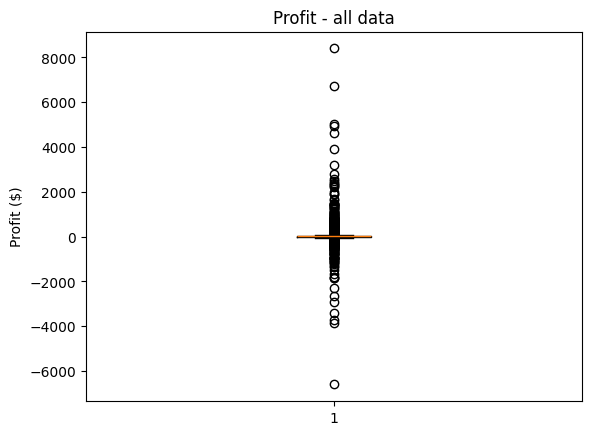

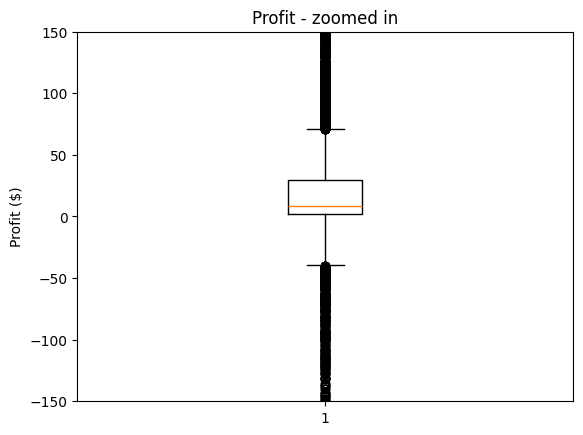

In [ ]:
# Box plot = the same IQR rule drawn as a picture
import matplotlib.pyplot as plt

plt.boxplot(df["Profit"])
plt.title("Profit - all data")
plt.ylabel("Profit ($)")
plt.show()

plt.boxplot(df["Profit"])
plt.ylim(-150, 150)          # zoom in so we can see the box
plt.title("Profit - zoomed in")
plt.ylabel("Profit ($)")
plt.show()

**Decision: we KEEP the outliers.** The worst losses all had 50–80% discounts; the best profits had 0% discount. These are real events and they *are* our story. Deleting them would delete most of the loss-making orders the models must learn from. Outliers hurt some models (Linear Regression, KMeans) more than others (tree models), so model choice is part of the answer.

**Phase 1 result:** 9,977 clean rows × 11 columns. 18.7% of orders lose money.

---
# Phase 2: Exploratory Data Analysis (EDA)
Before building models, we find the story in the data and check which inputs matter.

In [ ]:
# ---- Step 2.1: Size the problem in dollars ----
total_sales  = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_gain = df.loc[df["Profit"] > 0, "Profit"].sum()
total_loss = df.loc[df["Profit"] < 0, "Profit"].sum()

print("Total Sales   : $", round(total_sales, 2))
print("Total Profit  : $", round(total_profit, 2))
print("Profit margin :", round(total_profit / total_sales * 100, 2), "%")
print("\nProfit from good orders : $", round(total_gain, 2))
print("Loss from bad orders    : $", round(total_loss, 2))
print("Share of gains wiped out by losses:", round(abs(total_loss) / total_gain * 100, 1), "%")

Total Sales   : $ 2296195.59
Total Profit  : $ 286241.42
Profit margin : 12.47 %

Profit from good orders : $ 442354.41
Loss from bad orders    : $ -156112.99
Share of gains wiped out by losses: 35.3 %


By Category:
                     Sales     Profit  Margin %
Category                                       
Furniture        741306.31   18421.81      2.49
Office Supplies  718735.24  122364.66     17.02
Technology       836154.03  145454.95     17.40

By Region:
             Sales     Profit  Margin %
Region                                 
Central  500782.85   39655.88      7.92
East     678435.20   91506.31     13.49
South    391721.90   46749.43     11.93
West     725255.64  108329.81     14.94

Profit by Region and Category:
Category  Furniture  Office Supplies  Technology
Region                                          
Central    -2906.15          8864.59    33697.43
East        3058.22         40986.05    47462.04
South       6771.21         19986.39    19991.83
West       11498.53         52527.63    44303.65


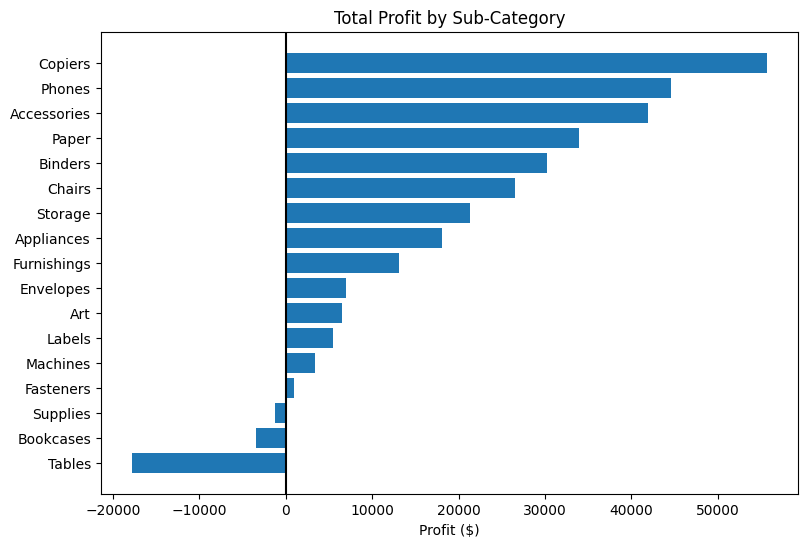

In [ ]:
# ---- Step 2.2: Where is money made and lost? ----
category_table = df.groupby("Category")[["Sales", "Profit"]].sum()
category_table["Margin %"] = category_table["Profit"] / category_table["Sales"] * 100
print("By Category:")
print(category_table.round(2))

region_table = df.groupby("Region")[["Sales", "Profit"]].sum()
region_table["Margin %"] = region_table["Profit"] / region_table["Sales"] * 100
print("\nBy Region:")
print(region_table.round(2))

region_category = df.pivot_table(index="Region", columns="Category", values="Profit", aggfunc="sum")
print("\nProfit by Region and Category:")
print(region_category.round(2))

sub_profit = df.groupby("Sub-Category")["Profit"].sum().sort_values()
plt.figure(figsize=(9, 6))
plt.barh(sub_profit.index, sub_profit.values)
plt.axvline(0, color="black")     # bars on the left of this line lose money
plt.title("Total Profit by Sub-Category")
plt.xlabel("Profit ($)")
plt.show()

**Findings:** Furniture has a **2.5% margin** vs ~17% for the other categories. **Tables (-$17.7K), Bookcases and Supplies** lose money overall. **Central** is the weakest region (7.9% margin) and **Furniture in Central** is the only negative Region × Category cell.

In [ ]:
# ---- Step 2.3: Does discount cause the losses? ----
print("Orders at each discount:")
print(df.groupby("Discount")["Profit"].count())
print("\nAverage profit at each discount:")
print(df.groupby("Discount")["Profit"].mean().round(2))
print("\n% of orders losing money at each discount:")
print((df.groupby("Discount")["Is_Loss"].mean() * 100).round(1))

high_discount_loss = df.loc[(df["Discount"] > 0.2) & (df["Profit"] < 0), "Profit"].sum()
print("\nLoss from orders with discount above 20%: $", round(high_discount_loss, 2))
print("Share of all losses:", round(high_discount_loss / total_loss * 100, 1), "%")

Orders at each discount:
Discount
0.00    4787
0.10      94
0.15      52
0.20    3653
0.30     226
0.32      27
0.40     206
0.45      11
0.50      66
0.60     138
0.70     418
0.80     299
Name: Profit, dtype: int64

Average profit at each discount:
Discount
0.00     67.02
0.10     96.06
0.15     27.29
0.20     24.72
0.30    -45.83
0.32    -88.56
0.40   -111.93
0.45   -226.65
0.50   -310.70
0.60    -43.08
0.70    -95.87
0.80   -102.12
Name: Profit, dtype: float64

% of orders losing money at each discount:
Discount
0.00      0.0
0.10      4.3
0.15     32.7
0.20     13.7
0.30     91.6
0.32    100.0
0.40     87.4
0.45    100.0
0.50    100.0
0.60    100.0
0.70    100.0
0.80    100.0
Name: Is_Loss, dtype: float64

Loss from orders with discount above 20%: $ -138496.95
Share of all losses: 88.7 %


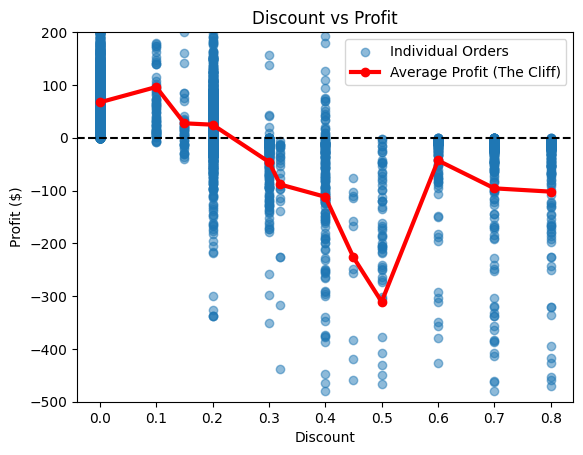

In [ ]:
# Visualising the insights for relation between discount & profit
plt.scatter(df["Discount"], df["Profit"], alpha=0.5, label="Individual Orders")

plt.axhline(0, color="black", linestyle="--")
plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit ($)")

# Calculate the average profit for each discount level
avg_profit_per_discount = df.groupby("Discount")["Profit"].mean().round(2)

# Plot the average profit as a bold red line to show the "cliff"
plt.plot(avg_profit_per_discount.index, avg_profit_per_discount.values, color="red", linewidth=3, marker="o", label="Average Profit (The Cliff)")

# Zoom in the y-axis to actually see the red line's movement
plt.ylim(-500, 200)

# Show the legend to identify the red line
plt.legend()

# Show the SINGLE merged plot
plt.show()

# Create the target for Phase 4: 1 = order lost money, 0 = it did not
df["Is_Loss"] = (df["Profit"] < 0) * 1

**The discount cliff:** up to 20% discount most orders still make money. **Above 20%, almost every order loses money** (100% of orders at 45% discount and above). Orders with discount above 20% are only ~14% of orders but cause **~89% of all losses**.

          Sales  Quantity  Discount  Profit
Sales      1.00      0.20     -0.03    0.48
Quantity   0.20      1.00      0.01    0.07
Discount  -0.03      0.01      1.00   -0.22
Profit     0.48      0.07     -0.22    1.00


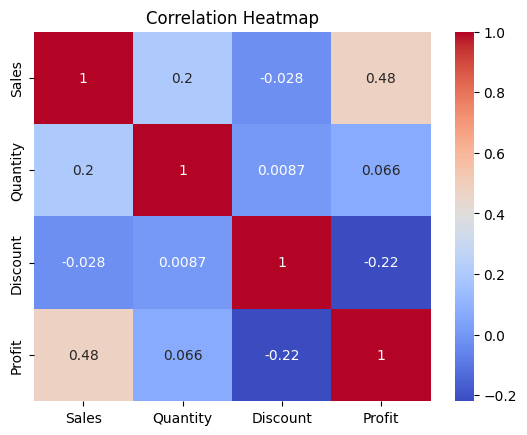

In [ ]:
# ---- Step 2.4: Correlation heatmap ----
numbers = df[["Sales", "Quantity", "Discount", "Profit"]]
corr = numbers.corr()
print(corr.round(2))

sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

**Puzzle:** discount clearly destroys profit, yet Discount–Profit correlation is only **-0.22 (weak)**.

Why?
Correlation measures **straight-line** relationships, and ours is a **cliff** (flat until 20%, then a crash). **A weak correlation does not mean no relationship.** This is why we compare Linear Regression (straight lines) with tree models (yes/no questions like "Discount > 0.2?").

---
# Phase 3: Regression — predict Profit ($)

**How we score a regression model:**
| Score | Meaning | Better when |
|---|---|---|
| **MAE** (Mean Absolute Error) | On average, how many $ the prediction is off | Lower |
| **RMSE** (Root Mean Squared Error) | Like MAE but punishes big misses more | Lower |
| **R²** | Share of the ups and downs in profit the model explains (1 = perfect, 0 = no better than guessing the average) | Closer to 1 |

In [ ]:
# ---- Step 3.1: Choose X (inputs) and y (answer) ----
feature_columns = ["Sales", "Quantity", "Discount",
                   "Category", "Sub-Category", "Region", "Segment", "Ship Mode"]

X = df[feature_columns]
y = df["Profit"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (9977, 8)
y shape: (9977,)


In [ ]:
# ---- Step 3.2: One-Hot Encoding ----
X_encoded = pd.get_dummies(X, dtype=int)

print("Columns before encoding:", X.shape[1])
print("Columns after encoding :", X_encoded.shape[1])   # 3 numbers + 3 + 17 + 4 + 3 + 4 = 34
print(X_encoded.head(3))

Columns before encoding: 8
Columns after encoding : 34
    Sales  Quantity  Discount  Category_Furniture  Category_Office Supplies  \
0  261.96         2       0.0                   1                         0   
1  731.94         3       0.0                   1                         0   
2   14.62         2       0.0                   0                         1   

   Category_Technology  Sub-Category_Accessories  Sub-Category_Appliances  \
0                    0                         0                        0   
1                    0                         0                        0   
2                    0                         0                        0   

   Sub-Category_Art  Sub-Category_Binders  ...  Region_East  Region_South  \
0                 0                     0  ...            0             1   
1                 0                     0  ...            0             1   
2                 0                     0  ...            0             0   

   Region_

In [ ]:
# ---- Step 3.3: Split into training (70%) and testing (30%) ----
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.3, random_state=42)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])

Training rows: 6983
Testing rows : 2994


In [ ]:
# ---- Step 3.4: Model 1 - Linear Regression ----
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

lin_model = LinearRegression()
lin_model.fit(X_train, y_train)            # learn from training data

train_pred = lin_model.predict(X_train)    # answers on data it studied
test_pred  = lin_model.predict(X_test)     # answers on hidden data

print("LINEAR REGRESSION")
print("Train -> MAE:", round(mean_absolute_error(y_train, train_pred), 2),
      " RMSE:", round(np.sqrt(mean_squared_error(y_train, train_pred)), 2),
      " R2:", round(r2_score(y_train, train_pred), 3))
print("Test  -> MAE:", round(mean_absolute_error(y_test, test_pred), 2),
      " RMSE:", round(np.sqrt(mean_squared_error(y_test, test_pred)), 2),
      " R2:", round(r2_score(y_test, test_pred), 3))

LINEAR REGRESSION
Train -> MAE: 60.02  RMSE: 183.76  R2: 0.377
Test  -> MAE: 58.67  RMSE: 207.35  R2: 0.242


In [ ]:
# ---- Step 3.5: Model 2 - Random Forest ----
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)   # 100 trees
rf_model.fit(X_train, y_train)

train_pred = rf_model.predict(X_train)
test_pred  = rf_model.predict(X_test)

print("RANDOM FOREST")
print("Train -> MAE:", round(mean_absolute_error(y_train, train_pred), 2),
      " RMSE:", round(np.sqrt(mean_squared_error(y_train, train_pred)), 2),
      " R2:", round(r2_score(y_train, train_pred), 3))
print("Test  -> MAE:", round(mean_absolute_error(y_test, test_pred), 2),
      " RMSE:", round(np.sqrt(mean_squared_error(y_test, test_pred)), 2),
      " R2:", round(r2_score(y_test, test_pred), 3))

RANDOM FOREST
Train -> MAE: 7.58  RMSE: 50.0  R2: 0.954
Test  -> MAE: 18.97  RMSE: 129.91  R2: 0.702


**Reading the results (Step 3.6 – compare and check over/underfitting):**

**Overfitting check:** Random Forest scores R² ~0.95 on training but ~0.70 on test. That gap means it memorised some of the training data (common for Random Forest). The test score is still far better than Linear Regression, so it's the model we choose, but the honest number to report is the **test** score.

This confirms the Phase 2 puzzle: the relationship is non-linear, so a tree-based model wins.

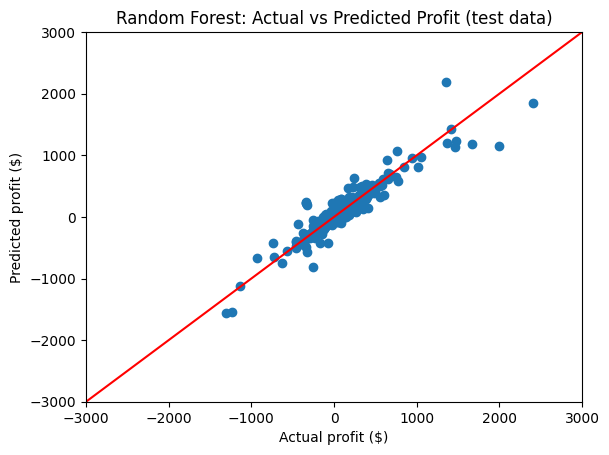

Sales                    0.649
Discount                 0.212
Quantity                 0.016
Sub-Category_Supplies    0.015
Sub-Category_Binders     0.014
Sub-Category_Copiers     0.013
Region_Central           0.010
Sub-Category_Machines    0.008
dtype: float64


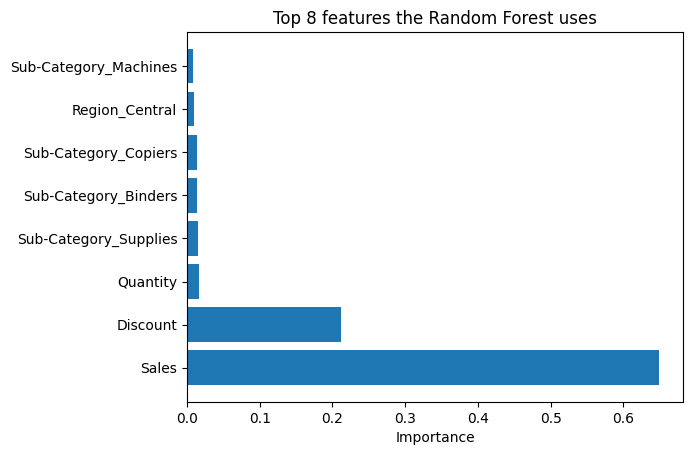

In [ ]:
# ---- Step 3.7: Actual vs predicted, and what the model relies on ----
plt.scatter(y_test, test_pred)
plt.plot([-3000, 3000], [-3000, 3000], color="red")   # perfect predictions would sit on this line
plt.xlim(-3000, 3000)
plt.ylim(-3000, 3000)
plt.title("Random Forest: Actual vs Predicted Profit (test data)")
plt.xlabel("Actual profit ($)")
plt.ylabel("Predicted profit ($)")
plt.show()

importance = pd.Series(rf_model.feature_importances_, index=X_encoded.columns)
importance = importance.sort_values(ascending=False).head(8)
print(importance.round(3))

plt.barh(importance.index, importance.values)
plt.title("Top 8 features the Random Forest uses")
plt.xlabel("Importance")
plt.show()

**Sales** and **Discount** are by far the most important inputs. Sales sets the size of the profit; Discount decides whether it's a gain or a loss.

In [ ]:
# ---- Step 3.8: Business use - a "what if" discount simulator ----
# Take one real Tables order and ask the model: what profit at different discounts?
table_orders = X_encoded[X_encoded["Sub-Category_Tables"] == 1]
one_order = table_orders.iloc[[0]].copy()
print("Order sales value: $", one_order["Sales"].values[0])

for d in [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]:
    one_order["Discount"] = d
    predicted = rf_model.predict(one_order)[0]
    print("Discount", int(d * 100), "% -> predicted profit: $", round(predicted, 2))

Order sales value: $ 957.5775
Discount 0 % -> predicted profit: $ 224.43
Discount 10 % -> predicted profit: $ 142.91
Discount 20 % -> predicted profit: $ 2.82
Discount 30 % -> predicted profit: $ -158.17
Discount 40 % -> predicted profit: $ -308.37
Discount 50 % -> predicted profit: $ -450.01


**Result:** for this \$958 table order, the model predicts about \$231 profit at 0% discount, roughly break-even at 20%, and about \$451 at 50%. The cliff again.

**Business output:** before approving a deal, a salesperson can check the predicted profit at the discount they want to give.

---
# Phase 4: Classification — flag loss-making orders

Now the answer is a category: **Is_Loss = 1 (loss) or 0 (no loss)**.

**Logistic Regression:** despite the name, it's a classification model. It calculates the **probability** that an order is a loss (0 to 1); above 0.5 → "loss".
**Decision Tree:** a flowchart of yes/no questions ("Discount > 0.25?") ending in an answer. Easy to explain to a manager.

**Why accuracy alone is not enough:** only ~19% of orders are losses. A lazy model that always says "no loss" would be 81% accurate and catch **zero** loss orders. So we also use:

| Score | Question it answers |
|---|---|
| **Precision** | When the model says "loss", how often is it right? |
| **Recall** | Of all real loss orders, how many did it catch? |
| **F1** | One number balancing precision and recall |
| **Confusion matrix** | Table of right and wrong answers of each kind |

For our business, **recall matters most**: a missed loss order costs real money; a false alarm only costs a manager's quick review.

In [ ]:
# ---- Step 4.1 & 4.2: Target and class balance ----
y_class = df["Is_Loss"]

print(y_class.value_counts())
print("\nShare of loss orders:", round(y_class.mean() * 100, 1), "%")

Is_Loss
0    8108
1    1869
Name: count, dtype: int64

Share of loss orders: 18.7 %


In [ ]:
# ---- Step 4.3: Split (same X_encoded as Phase 3 - it has no Profit, so no leakage) ----
# stratify keeps the same 81/19 ratio in both train and test
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y_class, test_size=0.3, random_state=42, stratify=y_class)

print("Loss share in train:", round(y_train.mean() * 100, 1), "%")
print("Loss share in test :", round(y_test.mean() * 100, 1), "%")

Loss share in train: 18.7 %
Loss share in test : 18.7 %


**Step 4.4 – handling imbalance:** we use `class_weight="balanced"`. This tells the model "a mistake on the rare class (loss) counts more", so it doesn't ignore loss orders.

In [ ]:
# ---- Step 4.5a: Model 1 - Logistic Regression ----
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

log_model = LogisticRegression(max_iter=1000, class_weight="balanced")
log_model.fit(X_train, y_train)
log_pred = log_model.predict(X_test)

print("LOGISTIC REGRESSION")
print("Train accuracy:", round(accuracy_score(y_train, log_model.predict(X_train)), 3))
print("Test accuracy :", round(accuracy_score(y_test, log_pred), 3))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, log_pred))
print(classification_report(y_test, log_pred, digits=3))

LOGISTIC REGRESSION
Train accuracy: 0.924
Test accuracy : 0.914

Confusion matrix:
[[2201  232]
 [  26  535]]
              precision    recall  f1-score   support

           0      0.988     0.905     0.945      2433
           1      0.698     0.954     0.806       561

    accuracy                          0.914      2994
   macro avg      0.843     0.929     0.875      2994
weighted avg      0.934     0.914     0.919      2994



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
# ---- Step 4.5b: Model 2 - Decision Tree ----
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)

print("DECISION TREE")
print("Train accuracy:", round(accuracy_score(y_train, tree_model.predict(X_train)), 3))
print("Test accuracy :", round(accuracy_score(y_test, tree_pred), 3))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, tree_pred))
print(classification_report(y_test, tree_pred, digits=3))

DECISION TREE
Train accuracy: 0.901
Test accuracy : 0.887

Confusion matrix:
[[2111  322]
 [  17  544]]
              precision    recall  f1-score   support

           0      0.992     0.868     0.926      2433
           1      0.628     0.970     0.762       561

    accuracy                          0.887      2994
   macro avg      0.810     0.919     0.844      2994
weighted avg      0.924     0.887     0.895      2994



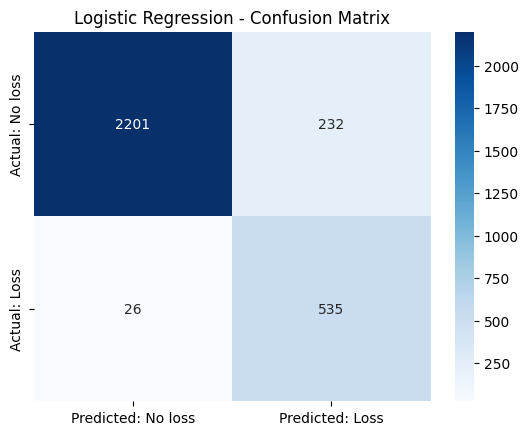

In [ ]:
# ---- Step 4.6: Confusion matrix as a picture (Logistic Regression) ----
cm = confusion_matrix(y_test, log_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted: No loss", "Predicted: Loss"],
            yticklabels=["Actual: No loss", "Actual: Loss"])
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

**Confusion matrix (Logistic Regression, test data):**

| | Predicted: No loss | Predicted: Loss |
|---|---|---|
| **Actual: No loss** | ~2,201 correct ✅ | ~232 false alarms |
| **Actual: Loss** | **~26 missed** ❌ | **~535 caught** ✅ |

- **Recall for losses ≈ 95%** → it catches 535 of 561 loss orders.
- **Precision ≈ 70%** → when it raises a flag, it's right 7 times out of 10.
- Accuracy ≈ 91%, train ≈ 92% vs test ≈ 91% → **no overfitting**.

Decision Tree: recall ≈ 97% but precision ≈ 63%. Logistic Regression has the better balance (F1 0.81 vs 0.76), so it's our main model; the tree is kept because it's easy to explain.

Discount                    0.828
Category_Office Supplies    0.065
Sub-Category_Storage        0.048
Sub-Category_Supplies       0.030
Sub-Category_Phones         0.016
Sales                       0.005
dtype: float64


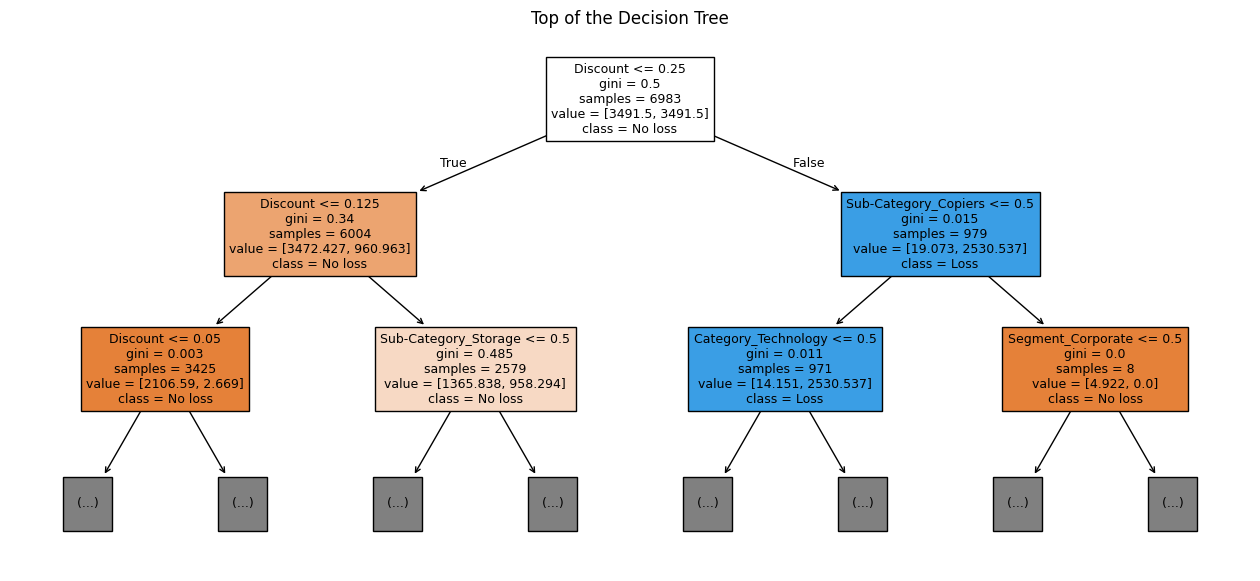

In [ ]:
# ---- Step 4.7: What pushes an order into loss? ----
from sklearn.tree import plot_tree

importance = pd.Series(tree_model.feature_importances_, index=X_encoded.columns)
print(importance.sort_values(ascending=False).head(6).round(3))

plt.figure(figsize=(16, 7))
plot_tree(tree_model, max_depth=2, feature_names=list(X_encoded.columns),
          class_names=["No loss", "Loss"], filled=True, fontsize=9)
plt.title("Top of the Decision Tree")
plt.show()

**Discount alone makes up over 80% of the tree's decisions.** The very first question the tree asks is about discount, the same cliff we found in EDA. The model has independently "discovered" the business rule.

---
# Phase 5: Clustering — group the states

**Unsupervised:** there is no answer column. **KMeans** puts states into K groups so that states in the same group are similar:
1. Pick K random centre points. 2. Each state joins its nearest centre. 3. Move each centre to the middle of its group. 4. Repeat until nothing changes.

Because KMeans measures **distance**, a column in hundreds of thousands (Sales) would drown out a column between 0 and 1 (Discount). So we **scale** first.

In [ ]:
# ---- Step 5.1: One row per state ----
state_df = df.groupby("State")[["Sales", "Profit", "Quantity"]].sum()
state_df["Avg_Discount"] = df.groupby("State")["Discount"].mean()

print("Number of states:", state_df.shape[0])
print(state_df.head().round(2))

Number of states: 49
                Sales    Profit  Quantity  Avg_Discount
State                                                  
Alabama      19510.64   5786.83       256          0.00
Arizona      35282.00  -3427.92       862          0.30
Arkansas     11678.13   4008.69       240          0.00
California  457576.27  76330.79      7649          0.07
Colorado     32108.12  -6527.86       693          0.32


In [ ]:
# ---- Step 5.2: Scale with StandardScaler ----
# After scaling, every column has average 0 and a similar spread
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
state_scaled = scaler.fit_transform(state_df)

print(pd.DataFrame(state_scaled, columns=state_df.columns).head().round(2))

   Sales  Profit  Quantity  Avg_Discount
0  -0.34   -0.00     -0.39         -0.66
1  -0.14   -0.54      0.07          1.75
2  -0.44   -0.11     -0.40         -0.66
3   5.14    4.08      5.23         -0.08
4  -0.18   -0.72     -0.06          1.85


K = 2  inertia: 93.2  silhouette: 0.784
K = 3  inertia: 32.9  silhouette: 0.699
K = 4  inertia: 23.6  silhouette: 0.605
K = 5  inertia: 15.8  silhouette: 0.607
K = 6  inertia: 10.7  silhouette: 0.588
K = 7  inertia: 8.0  silhouette: 0.579
K = 8  inertia: 6.0  silhouette: 0.483


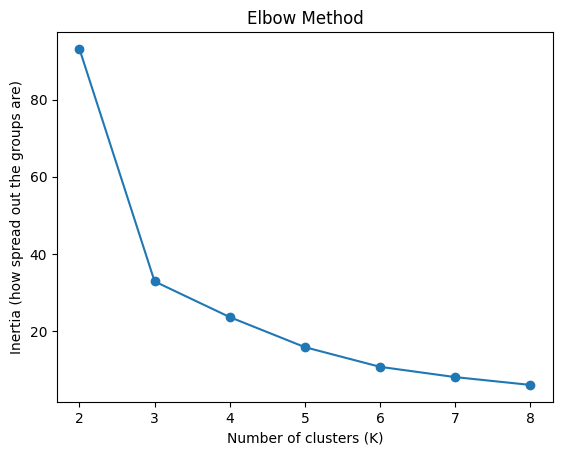

In [ ]:
# ---- Step 5.3: How many clusters? Elbow method + silhouette score ----
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = [2, 3, 4, 5, 6, 7, 8]
inertia_list = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(state_scaled)
    inertia_list.append(km.inertia_)
    score = silhouette_score(state_scaled, km.labels_)
    print("K =", k, " inertia:", round(km.inertia_, 1), " silhouette:", round(score, 3))

plt.plot(k_values, inertia_list, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia (how spread out the groups are)")
plt.show()

- **Inertia** = how far states are from their group centre (lower = tighter groups). The **elbow** is where adding more clusters stops helping much — here around **K = 3–4**.
- **Silhouette** (−1 to 1) = how well each state fits its own group vs the next group.

K = 2 has the highest silhouette, but it only splits the two giant states (California, New York) from everyone else — not useful. **K = 4** still has a good silhouette (~0.6), sits at the elbow, and gives groups a manager can act on. **We choose K = 4.** (Choosing K is a judgement that combines the numbers with business sense.)

In [ ]:
# ---- Step 5.4: Run KMeans with K = 4 ----
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans.fit(state_scaled)
state_df["Cluster"] = kmeans.labels_

# ---- Step 5.5: Read each cluster's average and give it a name ----
cluster_summary = state_df.groupby("Cluster").mean()
cluster_summary["States"] = state_df.groupby("Cluster").size()
print(cluster_summary.round(2))

def name_cluster(row):
    if row["Profit"] < 0:
        return "Problem: heavy discounts, losing money"
    elif row["Sales"] > 200000:
        return "Stars: biggest and most profitable"
    elif row["Sales"] > 50000:
        return "Healthy: mid-size, low discount, good profit"
    else:
        return "Small but steady"

cluster_names = {}
for cluster_number, row in cluster_summary.iterrows():
    cluster_names[cluster_number] = name_cluster(row)

state_df["Group"] = state_df["Cluster"].map(cluster_names)

for group in state_df["Group"].unique():
    print("\n" + group + ":")
    print(list(state_df[state_df["Group"] == group].index))

             Sales    Profit  Quantity  Avg_Discount  States
Cluster                                                     
0         13586.06   3847.72    199.97          0.02      32
1        384201.71  75173.13   5934.50          0.06       2
2         70530.99  -9825.91   1456.20          0.32      10
3         77545.67  22205.45    998.00          0.01       5

Small but steady:
['Alabama', 'Arkansas', 'Connecticut', 'Delaware', 'District of Columbia', 'Idaho', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana', 'Maine', 'Maryland', 'Massachusetts', 'Minnesota', 'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Hampshire', 'New Jersey', 'New Mexico', 'North Dakota', 'Oklahoma', 'Rhode Island', 'South Carolina', 'South Dakota', 'Utah', 'Vermont', 'West Virginia', 'Wisconsin', 'Wyoming']

Problem: heavy discounts, losing money:
['Arizona', 'Colorado', 'Florida', 'Illinois', 'North Carolina', 'Ohio', 'Oregon', 'Pennsylvania', 'Tennessee', 'Texas']

Stars: biggest and most profita

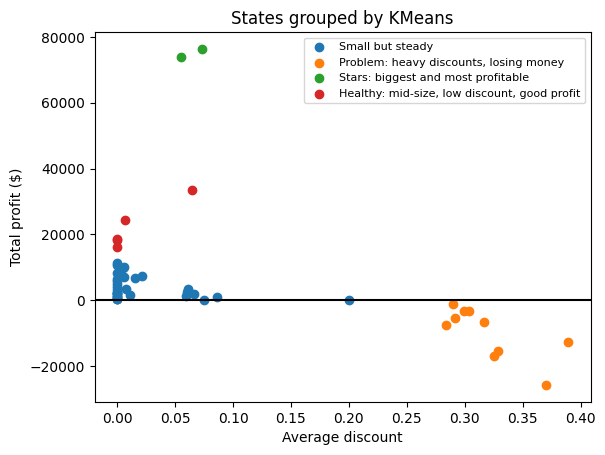

In [ ]:
# ---- Step 5.6: Plot the clusters ----
for group in state_df["Group"].unique():
    part = state_df[state_df["Group"] == group]
    plt.scatter(part["Avg_Discount"], part["Profit"], label=group)

plt.axhline(0, color="black")
plt.title("States grouped by KMeans")
plt.xlabel("Average discount")
plt.ylabel("Total profit ($)")
plt.legend(fontsize=8)
plt.show()

**Cluster story:**

| Group | Typical avg discount | What to do |
|---|---|---|
| **Stars** (California, New York) | ~6% | Protect: keep discounts low, invest in growth |
| **Healthy** (e.g. Washington, Michigan, Virginia) | ~1% | Copy their pricing discipline elsewhere |
| **Small but steady** (32 states) | ~2% | Low-cost growth, nothing broken |
| **Problem** (Texas, Ohio, Pennsylvania, Illinois, Florida, Arizona, Colorado, NC, Oregon, Tennessee) | **~32%** | **Cap discounts first.** These 10 states have big sales but lose money overall |

The clustering found, without being told, that the losing states are exactly the **heavy-discount** states.

---
# Phase 6: Cost of NOT using ML, and benefits of using it

### 6.1 Losses in our own data

In [ ]:
# ---- Step 6.1: The current loss, in dollars ----
print("Total lost on loss-making orders: $", round(abs(total_loss), 2))
print("Lost on orders with discount > 20%: $", round(abs(high_discount_loss), 2))

# How much of the test-set loss would the classifier have flagged in advance?
test_profit = df.loc[y_test.index, "Profit"]
real_losses = test_profit[test_profit < 0].sum()
caught_losses = test_profit[(test_profit < 0) & (log_pred == 1)].sum()

print("\nTest set - total loss on loss orders: $", round(abs(real_losses), 2))
print("Loss on orders the model flagged    : $", round(abs(caught_losses), 2))
print("Share of loss dollars flagged in advance:", round(caught_losses / real_losses * 100, 1), "%")

false_alarm_profit = test_profit[(test_profit >= 0) & (log_pred == 1)].sum()
print("\nProfit on false alarms (needs review, not blocking): $", round(false_alarm_profit, 2))

Total lost on loss-making orders: $ 156112.99
Lost on orders with discount > 20%: $ 138496.95

Test set - total loss on loss orders: $ 45176.17
Loss on orders the model flagged    : $ 44743.09
Share of loss dollars flagged in advance: 99.0 %

Profit on false alarms (needs review, not blocking): $ 6618.59


### 6.2 What the industry says about losses without data-driven pricing

- **Most discounts lose money.** EY found that about **70% of standard discounts and general promotions lose money**, and that **discounts above 20% perform worse**, the same threshold our data shows. ([EY](https://www.EY.com/content/dam/ey-unified-site/ey-com/en-us/services/strategy-transactions/documents/ey-can-smarter-pricing-and-promotion-reduce-the-emphasis-on-discounting.pdf))
- **Deeper discounts give diminishing returns.** Bain describes "discount disease": a typical fashion retailer spends **20–50% of net sales on markdowns**, and at one retailer **60% of in-store promotions lost money**. For one category the profit-maximising discount was **10%**, while the sales-maximising one was **50%**. ([Bain & Company, 2021](https://www.bain.com/de/insights/curing-the-discount-disease-in-soft-goods-retail/))
- **Small pricing errors are expensive.** A widely cited McKinsey study of large companies found that a **1% price improvement, with demand unchanged, raises operating profit by about 11%** on average. Over-discounting works the same way in reverse. ([IndustryWeek, citing McKinsey](https://www.industryweek.com/finance/software-systems/article/21955233/10-tips-to-better-pricing))

### 6.3 Benefits of using ML

- **Higher profit from analytics-driven pricing and promotion:** EY reports **gross profit up 8–12%** and revenue up 8–10% for companies that optimise pricing and promotions with analytics. ([EY](https://www.EY.com/content/dam/ey-unified-site/ey-com/en-us/services/strategy-transactions/documents/ey-can-smarter-pricing-and-promotion-reduce-the-emphasis-on-discounting.pdf))
- **Better return on discounts:** Bain estimates optimisation can raise the return on discount spending by **5–10%**, and in one pilot net profit margin rose **24%** vs control stores. ([Bain & Company](https://www.bain.com/de/insights/curing-the-discount-disease-in-soft-goods-retail/))
- **Real retail example:** German retailer Ernsting's family moved from fixed pricing rules to machine-learning price optimisation across its stores and reports higher sales and margins (vendor-reported case study). ([BestPractice.AI](https://bestpractice.ai/ai-use-cases/case-studies/consumer-retail/ernsting-s-family-optimises-pricing-decisions-while-improving-revenue-and-margins-with-machine-learning))

### 6.4 What each of our models gives the business

| Model | Business use | Value |
|---|---|---|
| Regression (Random Forest) | Predict profit before approving a deal; "what-if" discount simulator | Stops deals that look good on sales but lose money |
| Classification (Logistic Regression) | Automatic "risky order" warning | Flags ~95% of loss orders, covering ~99% of the loss dollars (test data) |
| Clustering (KMeans) | Different strategy per state group | Targets discount control on the 10 problem states |

# Phase 7: Conclusion

**The problem:** the store makes \$286K profit on \$2.3M sales, but **\$156K (35% of everything earned) leaks away** on loss-making orders.

**The cause (EDA):** discounts above 20%. Those orders are \~14% of orders but cause \~89% of losses. Furniture (especially Tables) and the Central region are hit hardest.

**What ML adds:**
1. **Regression:** Random Forest predicts profit far better than Linear Regression (test R² 0.70 vs 0.24) because the discount effect is a cliff, not a straight line.
2. **Classification:** Logistic Regression catches \~95% of loss orders in advance (\~99% of the loss dollars) with \~91% accuracy. Discount is the dominant factor.
3. **Clustering:** KMeans finds 4 state groups; 10 "problem" states average a 32% discount and lose money overall.

**Recommendations:**
1. Cap discounts at 20%; anything above needs manager approval, supported by the risky-order model.
2. Review Tables and Bookcases pricing.
3. Start discount control in the 10 problem states.
